<a href="https://colab.research.google.com/github/JanethGrimaldo/AI/blob/main/EO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicio 1

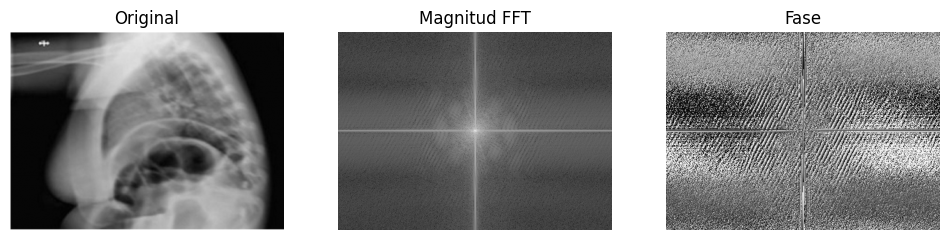

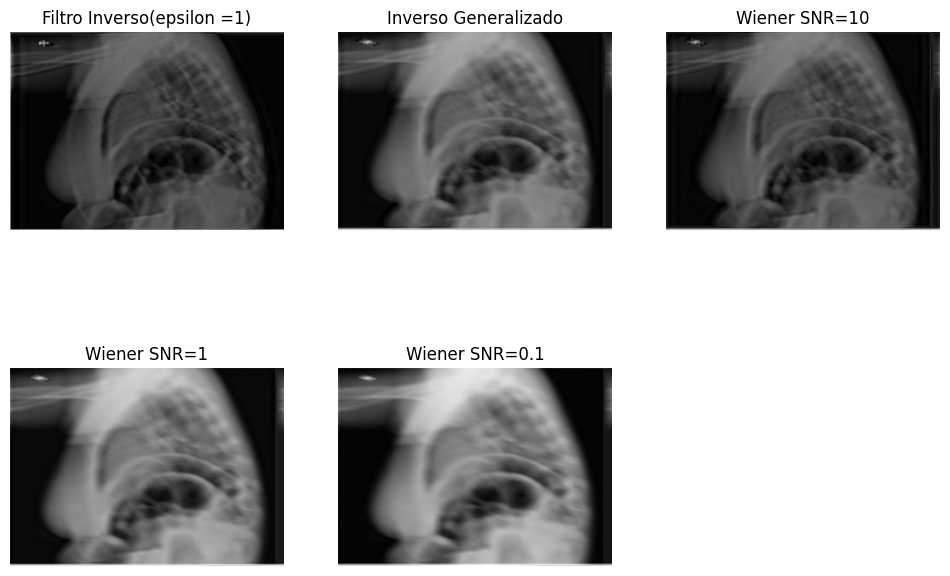

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("1.png", 0)
F = np.fft.fft2(img)
Fshift = np.fft.fftshift(F)

magnitud = np.log(np.abs(Fshift) + 1)
fase = np.angle(Fshift)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(magnitud, cmap='gray')
plt.title("Magnitud FFT")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(fase, cmap='gray')
plt.title("Fase")
plt.axis("off")

plt.show()

rows, cols = img.shape
PSF = np.zeros((rows, cols))
L = 20
centro = (rows // 2, cols // 2)

for i in range(L):
    x = int(centro[1] + i * np.cos(np.deg2rad(15)))
    y = int(centro[0] + i * np.sin(np.deg2rad(15)))

    if x < cols and y < rows:
        PSF[y, x] = 1

PSF = PSF / PSF.sum()
H = np.fft.fft2(np.fft.ifftshift(PSF))
G = np.fft.fft2(img)

eps = 1
F_inv = G / (H + eps)

img_inv = np.abs(np.fft.ifft2(F_inv))
a = 0.3
F_gen = (np.conj(H) / (np.abs(H)**2 + a)) * G

img_gen = np.abs(np.fft.ifft2(F_gen))
# filtros wiener
F_w10 = (np.conj(H) / (np.abs(H)**2 + (1 / 10))) * G
img_w10 = np.abs(np.fft.ifft2(F_w10))

F_w1 = (np.conj(H) / (np.abs(H)**2 + (1 / 1))) * G
img_w1 = np.abs(np.fft.ifft2(F_w1))

F_w01 = (np.conj(H) / (np.abs(H)**2 + (1 / 0.1))) * G
img_w01 = np.abs(np.fft.ifft2(F_w01))

plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(img_inv, cmap='gray')
plt.title(f"Filtro Inverso(epsilon ={eps})")
plt.axis("off")
plt.subplot(2, 3, 2)
plt.imshow(img_gen, cmap='gray')
plt.title("Inverso Generalizado")
plt.axis("off")
plt.subplot(2, 3, 3)
plt.imshow(img_w10, cmap='gray')
plt.title(f"Wiener SNR=10")
plt.axis("off")
plt.subplot(2, 3, 4)
plt.imshow(img_w1, cmap='gray')
plt.title(f"Wiener SNR=1")
plt.axis("off")
plt.subplot(2, 3, 5)
plt.imshow(img_w01, cmap='gray')
plt.title(f"Wiener SNR=0.1")
plt.axis("off")

plt.show()